In [13]:
import matplotlib.pyplot as plt

# Data
categories = ['Under $100', 'About $100', '$100 to $200', '$200 to $300', 'More than $300']
percentages = [22, 26, 39, 10, 3]
colors = ['lightblue', 'gold', 'cyan', 'pink', 'red']


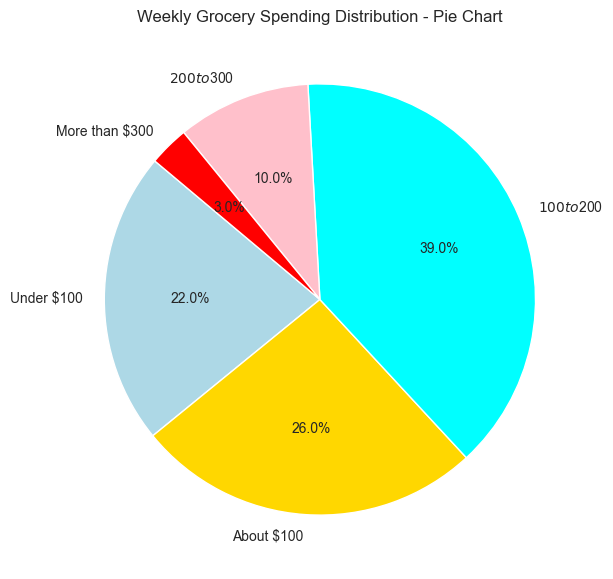

In [14]:

# Create pie chart
plt.figure(figsize=(7, 7))
plt.pie(percentages, labels=categories, autopct='%1.1f%%', colors=colors, startangle=140)
plt.title('Weekly Grocery Spending Distribution - Pie Chart')
plt.show()


In [15]:
########################################################################################

In [5]:
pip install cartopy

   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
    --------------------------------------- 0.3/11.0 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.0 MB 1.7 MB/s eta 0:00:07
   --- ------------------------------------ 1.0/11.0 MB 1.8 MB/s eta 0:00:06
   ---- ----------------------------------- 1.3/11.0 MB 1.8 MB/s eta 0:00:06
   ------ --------------------------------- 1.8/11.0 MB 2.0 MB/s eta 0:00:05
   -------- ------------------------------- 2.4/11.0 MB 2.1 MB/s eta 0:00:05
   ----------- ---------------------------- 3.1/11.0 MB 2.3 MB/s eta 0:00:04
   -------------- ------------------------- 3.9/11.0 MB 2.4 MB/s eta 0:00:03
   ---------------- ----------------------- 4.5/11.0 MB 2.5 MB/s eta 0:00:03
   -------------------- ------------------- 5.5/11.0 MB 2.8 MB/s eta 0:00:02
   ---------------------- ----------------- 6.3/11.0 MB 2.8 MB/s eta 0:00:02
   -------------------------- ------------- 7.3/11.0 MB 3.0 MB/s eta 0:00:02
   ----------


[notice] A new release of pip is available: 24.2 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# List of US states (excluding territories)
states = [
    "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado", "Connecticut", "Delaware", "Florida",
    "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky", "Louisiana", "Maine",
    "Maryland", "Massachusetts", "Michigan", "Minnesota", "Mississippi", "Missouri", "Montana", "Nebraska",
    "Nevada", "New Hampshire", "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota", "Ohio",
    "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island", "South Carolina", "South Dakota", "Tennessee", "Texas",
    "Utah", "Vermont", "Virginia", "Washington", "West Virginia", "Wisconsin", "Wyoming"
]

# Generate random case numbers (between 1,000 and 500,000)
np.random.seed(42)  # For reproducibility
cases = np.random.randint(1000, 500000, size=len(states))

# Create DataFrame
df = pd.DataFrame({"State": states, "Cases": cases})

# Normalize case values for color mapping
df["Color"] = df["Cases"] / df["Cases"].max()  # Scale between 0 and 1

# Load US states geometries using GeoPandas (Natural Earth data)
us_states = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
us_states = us_states[us_states['iso_a2'] == "US"]  # Filter for US only

# Manually mapping state names to match dataset
state_name_mapping = {
    "Alaska": "Alaska", "Alabama": "Alabama", "Arkansas": "Arkansas", "Arizona": "Arizona", "California": "California",
    "Colorado": "Colorado", "Connecticut": "Connecticut", "Delaware": "Delaware", "Florida": "Florida",
    "Georgia": "Georgia", "Hawaii": "Hawaii", "Idaho": "Idaho", "Illinois": "Illinois", "Indiana": "Indiana",
    "Iowa": "Iowa", "Kansas": "Kansas", "Kentucky": "Kentucky", "Louisiana": "Louisiana", "Maine": "Maine",
    "Maryland": "Maryland", "Massachusetts": "Massachusetts", "Michigan": "Michigan", "Minnesota": "Minnesota",
    "Mississippi": "Mississippi", "Missouri": "Missouri", "Montana": "Montana", "Nebraska": "Nebraska",
    "Nevada": "Nevada", "New Hampshire": "New Hampshire", "New Jersey": "New Jersey", "New Mexico": "New Mexico",
    "New York": "New York", "North Carolina": "North Carolina", "North Dakota": "North Dakota", "Ohio": "Ohio",
    "Oklahoma": "Oklahoma", "Oregon": "Oregon", "Pennsylvania": "Pennsylvania", "Rhode Island": "Rhode Island",
    "South Carolina": "South Carolina", "South Dakota": "South Dakota", "Tennessee": "Tennessee", "Texas": "Texas",
    "Utah": "Utah", "Vermont": "Vermont", "Virginia": "Virginia", "Washington": "Washington",
    "West Virginia": "West Virginia", "Wisconsin": "Wisconsin", "Wyoming": "Wyoming"
}

# Map the data to the states geometries
us_states["State"] = us_states["name"].map(state_name_mapping)
us_states = us_states.merge(df, on="State", how="left").fillna(0)

# Plot the US states with case-based color mapping
fig, ax = plt.subplots(1, 1, figsize=(12, 8))
us_states.plot(column="Cases", cmap="Oranges", linewidth=0.8, edgecolor="black", legend=True, ax=ax)

# Add title
plt.title("COVID-19 Cases by State (Darker = More Cases)", fontsize=14)
plt.axis("off")

# Show plot
plt.show()


AttributeError: The geopandas.dataset has been deprecated and was removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.

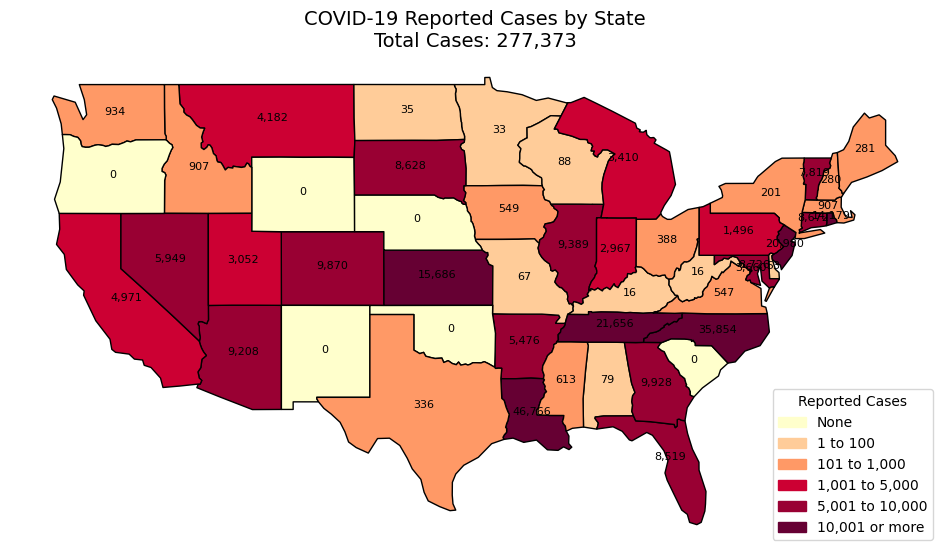

In [33]:
import geopandas as gpd
import matplotlib.pyplot as plt
import random

# Load the U.S. states shapefile (Update the path accordingly)
us_map = gpd.read_file("ne_110m_admin_1_states_provinces/ne_110m_admin_1_states_provinces.shp")
# us_map = gpd.read_file("/path/to/ne_110m_admin_1_states_provinces.shp")

# Filter to include only U.S. states
us_map = us_map[us_map['admin'] == "United States of America"]
us_map = us_map[~us_map['name'].isin(['Alaska', 'Hawaii'])]

# Define case categories
case_categories = {
    "None": (0, 0),
    "1 to 100": (1, 100),
    "101 to 1,000": (101, 1000),
    "1,001 to 5,000": (1001, 5000),
    "5,001 to 10,000": (5001, 10000),
    "10,001 or more": (10001, 50000)
}

# Assign random case numbers based on the categories
case_data = {}
for state in us_map['name']:
    category = random.choice(list(case_categories.keys()))
    case_data[state] = random.randint(*case_categories[category])

# Map states to their case numbers
us_map['cases'] = us_map['name'].map(case_data)

# Define color mapping
color_bins = {
    "None": "#ffffcc",
    "1 to 100": "#ffcc99",
    "101 to 1,000": "#ff9966",
    "1,001 to 5,000": "#cc0033",
    "5,001 to 10,000": "#990033",
    "10,001 or more": "#660033"
}

# Function to assign colors based on case numbers
def assign_color(value):
    for category, (low, high) in case_categories.items():
        if low <= value <= high:
            return color_bins[category]
    return "#ffffcc"

us_map['color'] = us_map['cases'].apply(assign_color)

# Plot the map
fig, ax = plt.subplots(1, 1, figsize=(12, 7))
us_map.plot(ax=ax, color=us_map['color'], edgecolor='black')

# Add case labels to each state
for idx, row in us_map.iterrows():
    plt.text(row.geometry.centroid.x, row.geometry.centroid.y, 
             f"{row['cases']:,}", fontsize=8, ha="center", color="black")

# Add legend
legend_patches = [mpatches.Patch(color=color, label=label) for label, color in color_bins.items()]
ax.legend(handles=legend_patches, title="Reported Cases", loc="lower right")

# Display total cases in the title
total_cases = us_map['cases'].sum()
ax.set_title(f"COVID-19 Reported Cases by State\nTotal Cases: {total_cases:,}", fontsize=14)

plt.axis("off")
plt.show()